# GTSinger 100: Frozen-sample EDA and Basic Pitch preparation

**Executed scope:** Read-only sample verification, descriptive EDA and Basic Pitch preparation. No Basic Pitch installation, inference, tuning or test evaluation.

The existing sample and all its manifests are frozen. Test metadata/header summaries are descriptive only; they are not used to select model settings. The sampling/export scripts are deliberately not invoked.

## 1. Configuration and safety helpers

In [1]:
from pathlib import Path
import sys, json, datetime, subprocess
import pandas as pd
import numpy as np
import soundfile as sf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd()/'GTSinger_100_unique_sample']
SAMPLE_ROOT = next((p.resolve() for p in candidates if (p/'selected_100.csv').is_file()), None)
if SAMPLE_ROOT is None:
    raise FileNotFoundError('Set SAMPLE_ROOT to the folder containing selected_100.csv')
SELECTED_100_CSV = SAMPLE_ROOT/'selected_100.csv'
SELECTED_RECORDINGS_CSV = SAMPLE_ROOT/'selected_recordings.csv'
SELECTED_FILES_CSV = SAMPLE_ROOT/'selected_files.csv'
SPLIT_MANIFEST_CSV = SAMPLE_ROOT/'split_manifest.csv'
RUN_BASIC_PITCH = False
RUN_FINAL_TEST = False
if RUN_BASIC_PITCH or RUN_FINAL_TEST:
    raise PermissionError('This executed Option A notebook prohibits inference. Obtain separate approval.')
EDA_OUT = SAMPLE_ROOT/'eda_outputs'
BP_OUT = SAMPLE_ROOT/'basic_pitch_runs'
REPORTS_OUT = SAMPLE_ROOT/'reports'
CHARTS_OUT = EDA_OUT/'charts'
for p in [EDA_OUT, BP_OUT, REPORTS_OUT, CHARTS_OUT, SAMPLE_ROOT/'notebooks']:
    p.mkdir(parents=True, exist_ok=True)
print('Sample root:', SAMPLE_ROOT)
print('Interpreter:', sys.executable)
print('RUN_BASIC_PITCH =', RUN_BASIC_PITCH, '| RUN_FINAL_TEST =', RUN_FINAL_TEST)

Sample root: C:\Users\dtpz2\Documents\Daphne documents\projects\datamining\GTSinger_100_unique_sample
Interpreter: C:\Users\dtpz2\Documents\Daphne documents\projects\datamining\.venv\Scripts\python.exe
RUN_BASIC_PITCH = False | RUN_FINAL_TEST = False


In [2]:
"""Read-only frozen-input helpers for approved Option A. No model imports at module load."""
from pathlib import Path
import hashlib, json, sys, platform, importlib.util, importlib.metadata, shutil
import pandas as pd
OUTPUT_DIRS={'eda_outputs','basic_pitch_runs','reports','notebooks'}
ROLES={'audio','json','musicxml','textgrid'}
SPLITS=['train','val','test']

def require_train_val_permission(approved,splits):
    if not approved: raise PermissionError('Inference is disabled: separate user approval required.')
    if not splits or not set(splits)<= {'train','val'}: raise PermissionError('Test inference is locked; this runner accepts train/val only.')

def safe_path(root,relative):
    root=Path(root).resolve(); path=(root/relative).resolve()
    if not path.is_relative_to(root): raise ValueError('Path escapes sample root: '+str(relative))
    return path

def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()

def snapshot(root):
    root=Path(root)
    return {p.relative_to(root).as_posix():sha(p) for p in sorted(root.rglob('*')) if p.is_file() and p.relative_to(root).parts[0] not in OUTPUT_DIRS}

def save_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2,sort_keys=True)+'\n',encoding='utf-8')

## 2. Frozen marker and immutable baseline
The snapshot hashes every pre-existing file outside the four new output directories, including selected sources, reserves, exported copies, original scripts and manifests. The baseline is retained across reruns.

In [3]:
marker = SAMPLE_ROOT/'SAMPLE_FROZEN_DO_NOT_RESAMPLE.txt'
if not marker.exists():
    marker.write_text('This 100-song GTSinger sample is frozen.\nDo not resample, replace, rebalance, or modify raw selected files.\nUse selected_100.csv, selected_recordings.csv, selected_files.csv, and split_manifest.csv as source of truth.\n', encoding='utf-8')
current_baseline = snapshot(SAMPLE_ROOT)
baseline_path = REPORTS_OUT/'frozen_baseline_sha256.json'
if baseline_path.exists():
    baseline = json.loads(baseline_path.read_text(encoding='utf-8'))
    if baseline != current_baseline:
        raise RuntimeError('Existing immutable baseline differs. Stop; do not regenerate the sample.')
else:
    baseline = current_baseline
    save_json(baseline_path, baseline)
print('Protected files hashed:', len(baseline))

Protected files hashed: 12230


## 3. Load the frozen manifests
All columns are initially read as strings to preserve identifiers and leading zeros. No source CSV is normalized or rewritten.

In [4]:
songs = pd.read_csv(SELECTED_100_CSV, dtype=str, keep_default_na=False)
recordings = pd.read_csv(SELECTED_RECORDINGS_CSV, dtype=str, keep_default_na=False)
files = pd.read_csv(SELECTED_FILES_CSV, dtype=str, keep_default_na=False)
splits = pd.read_csv(SPLIT_MANIFEST_CSV, dtype=str, keep_default_na=False)
source = json.loads((SAMPLE_ROOT/'hf_source_manifest.json').read_text(encoding='utf-8'))
original_report = json.loads((SAMPLE_ROOT/'validation_report.json').read_text(encoding='utf-8'))
for name, frame in [('selected_100',songs),('selected_recordings',recordings),('selected_files',files),('split_manifest',splits)]:
    print(name, frame.shape, '\n  columns:', ', '.join(frame.columns))
display(songs[['sample_id','canonical_title','language','singer','split','recording_count']].head(10))

selected_100 (100, 17) 
  columns: language, singer, vocal_range, technique_context, literal_title, subgroup, canonical_title, canonical_song_id, revision, selected_relative_folder, recording_count, split, sample_id, download_status, validation_status, replacement_of, notes
selected_recordings (858, 21) 
  columns: recording_id, canonical_song_id, language, singer, vocal_range, technique_context, subgroup, relative_folder, clip_stem, sample_id, split, revision, duration_seconds_if_validated, sample_rate, channels, subtype, validation_status, audio_path, json_path, musicxml_path, textgrid_path
selected_files (3432, 13) 
  columns: sample_id, recording_id, role, hf_path, local_path, export_path, expected_size, actual_size, hf_oid_or_sha256_if_available, hf_hash_type, local_sha256, status, revision
split_manifest (100, 5) 
  columns: sample_id, canonical_song_id, selected_relative_folder, split, revision


,sample_id,canonical_title,language,singer,split,recording_count
0,GTS001,你给我听好,Chinese,ZH-Tenor-1,train,8
1,GTS002,光阴的故事,Chinese,ZH-Tenor-1,test,8
2,GTS003,多远都要在一起,Chinese,ZH-Alto-1,train,8
3,GTS004,失落沙洲,Chinese,ZH-Alto-1,train,8
4,GTS005,崇拜,Chinese,ZH-Tenor-1,train,8
5,GTS006,平凡的一天,Chinese,ZH-Alto-1,val,7
6,GTS007,我好想你,Chinese,ZH-Alto-1,train,7
7,GTS008,时间煮雨,Chinese,ZH-Alto-1,train,8
8,GTS009,末班车,Chinese,ZH-Tenor-1,val,8
9,GTS010,空白格,Chinese,ZH-Tenor-1,train,8


## 4. Hard structural checks
Any failed check stops before EDA or Basic Pitch preparation. Required roles use the actual manifest labels: `audio`, `json`, `musicxml`, `textgrid`.

In [5]:
checks = {}
checks['exactly_100_songs'] = len(songs) == 100
checks['canonical_song_id_unique'] = songs.canonical_song_id.is_unique
checks['one_version_per_song'] = songs.selected_relative_folder.is_unique and songs.sample_id.is_unique
checks['split_counts_60_20_20'] = songs.split.value_counts().to_dict() == {'train':60,'val':20,'test':20}
checks['no_cross_split_song_leakage'] = songs.groupby('canonical_song_id').split.nunique().eq(1).all()
checks['nine_languages'] = songs.language.nunique() == 9
checks['twenty_singers'] = songs.singer.nunique() == 20
checks['four_vocal_ranges'] = set(songs.vocal_range) == {'Alto','Bass','Soprano','Tenor'}
checks['recording_ids_unique'] = recordings.recording_id.is_unique
checks['file_paths_unique'] = files.hf_path.is_unique
checks['exactly_four_roles_per_recording'] = len(files) == 4*len(recordings) and set(files.recording_id) == set(recordings.recording_id) and all(len(g)==4 and set(g.role)==ROLES for _,g in files.groupby('recording_id'))
checks['revision_matches_frozen_source'] = all(set(df.revision)=={source['revision']} for df in [songs,recordings,files,splits])
checks['split_manifest_exact_match'] = songs[['sample_id','canonical_song_id','selected_relative_folder','split','revision']].sort_values('sample_id').reset_index(drop=True).equals(splits.sort_values('sample_id').reset_index(drop=True))
checks['all_songs_have_recordings'] = set(recordings.sample_id)==set(songs.sample_id)
checks['recording_counts_match'] = all((recordings.sample_id==s.sample_id).sum()==int(s.recording_count) for s in songs.itertuples())
song_map = songs.set_index('sample_id').to_dict('index')
checks['recordings_match_selected_folder_and_split'] = all(r.sample_id in song_map and r.relative_folder==song_map[r.sample_id]['selected_relative_folder'] and r.canonical_song_id==song_map[r.sample_id]['canonical_song_id'] and r.split==song_map[r.sample_id]['split'] for r in recordings.itertuples())
record_map = recordings.set_index('recording_id').to_dict('index')
checks['files_match_recording_manifest'] = all(f.recording_id in record_map and f.sample_id==record_map[f.recording_id]['sample_id'] and f.local_path==record_map[f.recording_id][f.role+'_path'] and f.hf_path.rsplit('/',1)[0]==record_map[f.recording_id]['relative_folder'] and f.export_path=='data/'+record_map[f.recording_id]['split']+'/'+f.hf_path for f in files.itertuples())
checks = {k:bool(v) for k,v in checks.items()}
save_json(REPORTS_OUT/'frozen_structure_checks.json',checks)
display(pd.DataFrame(checks.items(),columns=['check','passed']))
if not all(checks.values()): raise RuntimeError('Frozen structure failed: '+str([k for k,v in checks.items() if not v]))

,check,passed
0,exactly_100_songs,True
1,canonical_song_id_unique,True
2,one_version_per_song,True
3,split_counts_60_20_20,True
4,no_cross_split_song_leakage,True
5,nine_languages,True
6,twenty_singers,True
7,four_vocal_ranges,True
8,recording_ids_unique,True
9,file_paths_unique,True


## 5. File integrity and source-role validation
Verify SHA256/size for both source files and exported copies. Parse JSON/MusicXML and decode TextGrid text read-only. Audio headers and durations are checked in the next section; the original full-decode results remain intact.

In [6]:
import xml.etree.ElementTree as ET
issues=[]
integrity_rows=[]
for f in files.itertuples():
    for location in ['local_path','export_path']:
        rel=getattr(f,location)
        try:
            path=safe_path(SAMPLE_ROOT,rel)
            if not path.is_file(): raise FileNotFoundError(rel)
            size=path.stat().st_size
            if size!=int(f.expected_size) or size!=int(f.actual_size): raise ValueError('Size differs from frozen manifest')
            observed=sha(path)
            if observed!=f.local_sha256: raise ValueError('SHA256 differs from frozen manifest')
            integrity_rows.append(dict(recording_id=f.recording_id,role=f.role,location=location,path=rel,size=size,sha256=observed,status='passed'))
        except Exception as exc:
            issues.append(dict(recording_id=f.recording_id,role=f.role,path=rel,error=str(exc)))
    try:
        path=safe_path(SAMPLE_ROOT,f.local_path)
        if f.role=='json': json.loads(path.read_text(encoding='utf-8-sig'))
        elif f.role=='musicxml':
            tag=ET.parse(path).getroot().tag.rsplit('}',1)[-1]
            if tag not in {'score-partwise','score-timewise'}: raise ValueError('Unexpected XML root')
        elif f.role=='textgrid':
            b=path.read_bytes(); text=b.decode('utf-16' if b.startswith((b'\xff\xfe',b'\xfe\xff')) else 'utf-8-sig')
            if not text.strip() or 'TextGrid' not in text[:512]: raise ValueError('Invalid/empty TextGrid')
    except Exception as exc: issues.append(dict(recording_id=f.recording_id,role=f.role,path=f.local_path,error=str(exc)))
expected_export_paths=set(files.export_path)
actual_export_paths={p.relative_to(SAMPLE_ROOT).as_posix() for p in (SAMPLE_ROOT/'data').rglob('*') if p.is_file()}
checks['export_contains_only_selected_files']=expected_export_paths==actual_export_paths
checks['selected_files_intact']=not issues
pd.DataFrame(integrity_rows).to_csv(EDA_OUT/'file_integrity_checks.csv',index=False)
pd.DataFrame(issues,columns=['recording_id','role','path','error']).to_csv(EDA_OUT/'missing_invalid_files.csv',index=False)
save_json(REPORTS_OUT/'frozen_verification.json',dict(passed=all(checks.values()),checks=checks,issues=issues,revision=source['revision']))
if not all(checks.values()): raise RuntimeError('File integrity failed; no repair/resampling permitted.')
print('Integrity checks passed:',len(integrity_rows),'source/export copies;',len(files),'selected source files; issues:',len(issues))

Integrity checks passed: 6864 source/export copies; 3432 selected source files; issues: 0


## 6. Read-only audio duration audit
Use soundfile headers; compare measured duration with the frozen recording manifest. This is not a new model evaluation or audio transformation.

In [7]:
duration_rows=[]
for r in recordings.itertuples():
    try:
        info=sf.info(str(safe_path(SAMPLE_ROOT,r.audio_path)))
        duration=info.frames/info.samplerate
        if duration<=0 or not np.isclose(duration,float(r.duration_seconds_if_validated),rtol=0,atol=1e-8):
            raise ValueError('Invalid duration or disagreement with frozen manifest')
        duration_rows.append(dict(sample_id=r.sample_id,recording_id=r.recording_id,split=r.split,language=r.language,singer=r.singer,vocal_range=r.vocal_range,technique_context=r.technique_context,subgroup=r.subgroup,audio_path=r.audio_path,duration_seconds=duration,sample_rate=info.samplerate,channels=info.channels,subtype=info.subtype,frames=info.frames))
    except Exception as exc: issues.append(dict(recording_id=r.recording_id,role='audio',path=r.audio_path,error=str(exc)))
pd.DataFrame(issues,columns=['recording_id','role','path','error']).to_csv(EDA_OUT/'missing_invalid_files.csv',index=False)
checks['audio_headers_and_durations_valid']=not issues and len(duration_rows)==len(recordings)
save_json(REPORTS_OUT/'frozen_verification.json',dict(passed=all(checks.values()),checks=checks,issues=issues,revision=source['revision']))
if not checks['audio_headers_and_durations_valid']: raise RuntimeError('Audio header/duration audit failed')
durations=pd.DataFrame(duration_rows)
durations.to_csv(EDA_OUT/'wav_duration_summary.csv',index=False)
print('Recordings:',len(durations),'| Total hours:',round(durations.duration_seconds.sum()/3600,4))
display(durations[['duration_seconds','sample_rate','channels']].describe())

Recordings: 858 | Total hours: 2.5149


,duration_seconds,sample_rate,channels
count,858.000000,858.0,858.0
mean,10.552029,48000.0,1.0
std,3.470114,0.0,0.0
min,3.831000,48000.0,1.0
25%,8.241500,48000.0,1.0
50%,9.840000,48000.0,1.0
75%,11.953224,48000.0,1.0
max,26.431000,48000.0,1.0


## 7. EDA tables
Song counts and recording/duration counts use different units and are labeled accordingly. Category tables contain song counts, not phoneme-level technique counts.

In [8]:
tables={}
def store(name,frame):
    frame.to_csv(EDA_OUT/(name+'.csv'),index=True)
    tables[name]=frame
    return frame
store('songs_by_split',songs.groupby('split').size().reindex(SPLITS).to_frame('songs'))
store('recordings_by_split',recordings.groupby('split').size().reindex(SPLITS).to_frame('recordings'))
store('files_by_role',files.groupby('role').size().to_frame('files'))
files_with_split=files.merge(recordings[['recording_id','split']],on='recording_id',validate='many_to_one')
store('files_by_role_by_split',pd.crosstab(files_with_split.role,files_with_split.split).reindex(columns=SPLITS,fill_value=0))
for field in ['language','singer','vocal_range','technique_context','subgroup']:
    store(field+'_by_split',pd.crosstab(songs[field],songs.split).reindex(columns=SPLITS,fill_value=0))
for field in ['split','language']:
    table=durations.groupby(field).duration_seconds.agg(recordings='count',total_seconds='sum',mean_seconds='mean',median_seconds='median',min_seconds='min',max_seconds='max')
    table['total_hours']=table.total_seconds/3600
    if field=='split': table=table.reindex(SPLITS)
    store('duration_by_'+field,table)
store('duration_language_by_split',pd.pivot_table(durations,index='language',columns='split',values='duration_seconds',aggfunc='sum',fill_value=0).reindex(columns=SPLITS))
store('audio_formats',durations.groupby(['sample_rate','channels','subtype']).size().to_frame('recordings'))
store('excerpts_per_song',durations.groupby('sample_id').agg(recordings=('recording_id','size'),total_seconds=('duration_seconds','sum')))
for name in ['songs_by_split','recordings_by_split','files_by_role','language_by_split','vocal_range_by_split','duration_by_split']:
    print(name); display(tables[name])

songs_by_split


,songs
split,
train,60
val,20
test,20


recordings_by_split


,recordings
split,
train,534
val,160
test,164


files_by_role


,files
role,
audio,858
json,858
musicxml,858
textgrid,858


... (2 outputs left out)

vocal_range_by_split


split,train,val,test
vocal_range,,,
Alto,15,5,5
Bass,8,3,3
Soprano,18,6,6
Tenor,19,6,6


duration_by_split


,recordings,total_seconds,mean_seconds,median_seconds,min_seconds,max_seconds,total_hours
split,,,,,,,
train,534,5637.087667,10.556344,9.80500,3.831,26.171813,1.565858
val,160,1663.180833,10.394880,9.72399,5.898,24.085000,0.461995
test,164,1753.371958,10.691292,10.11350,3.843,26.431000,0.487048


## 8. EDA charts
PNG charts are embedded below and saved separately under `eda_outputs/charts/`. SVG copies are also saved for reports.

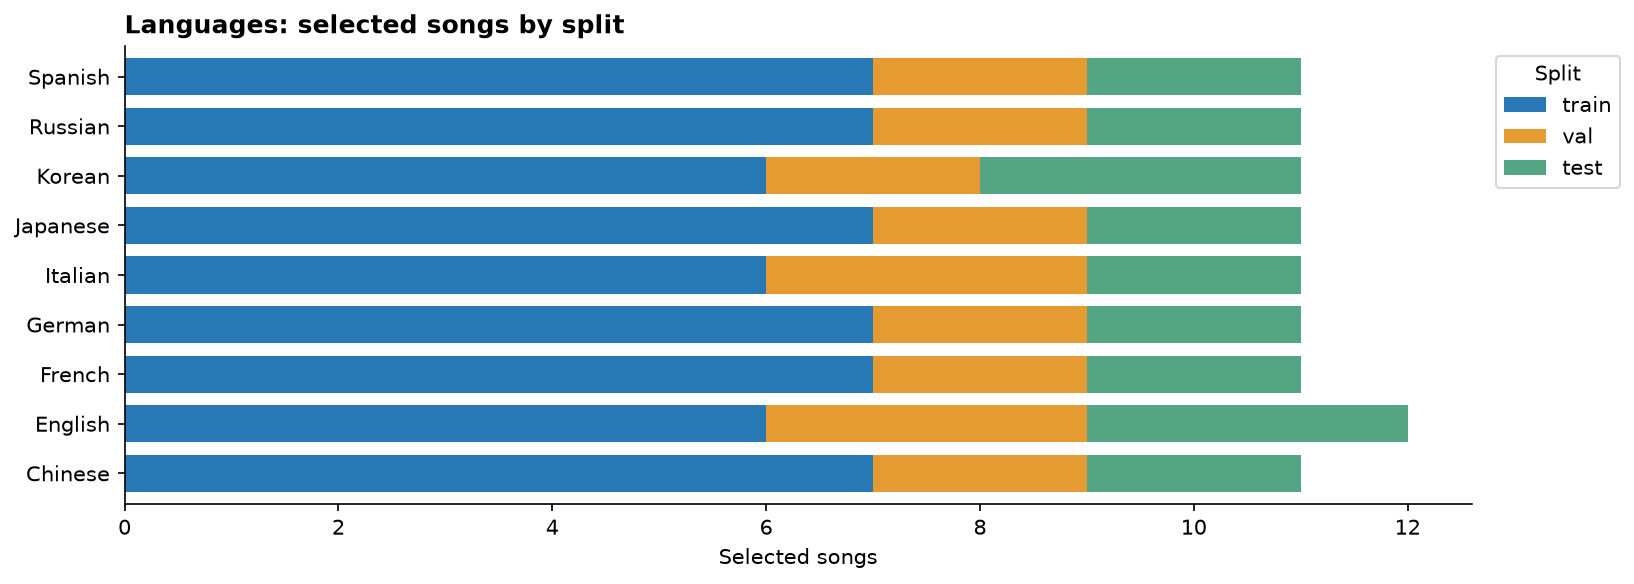

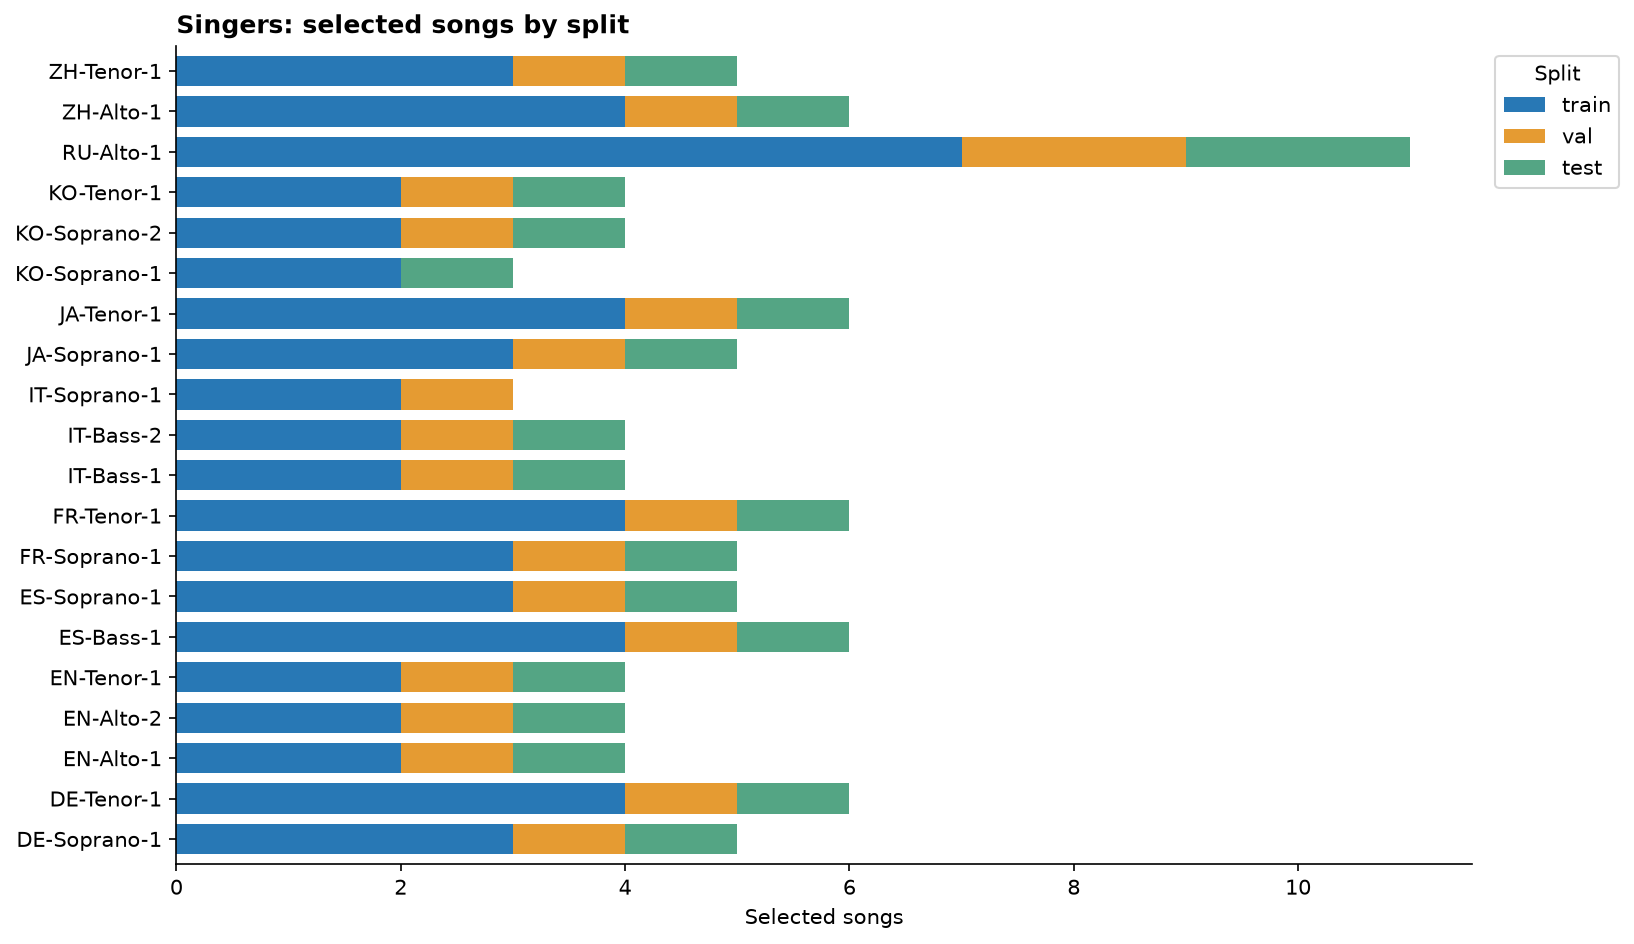

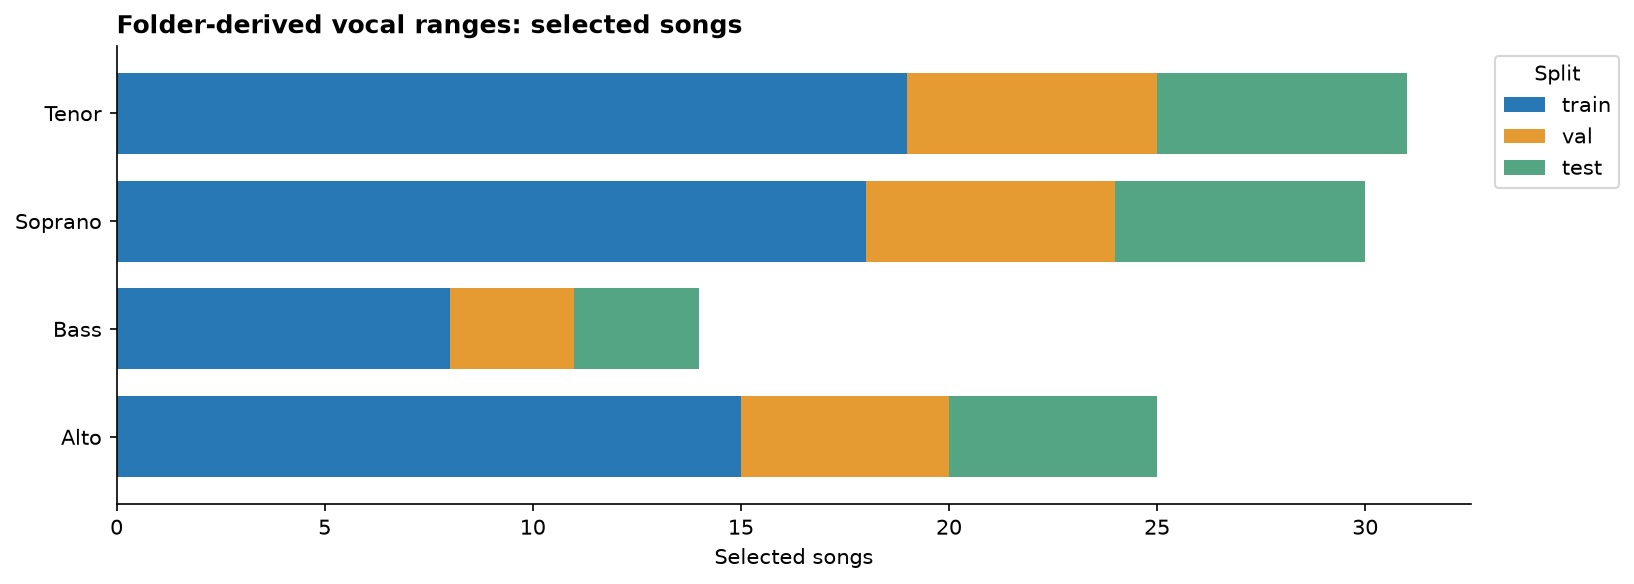

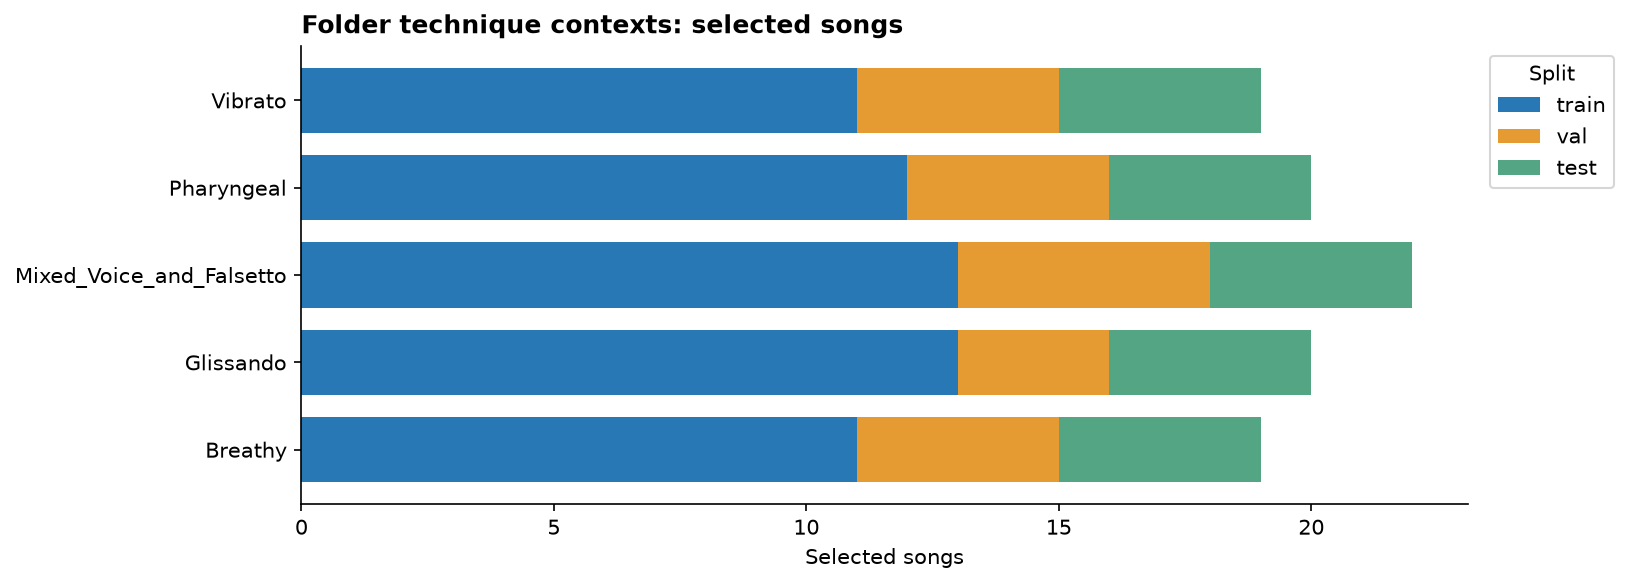

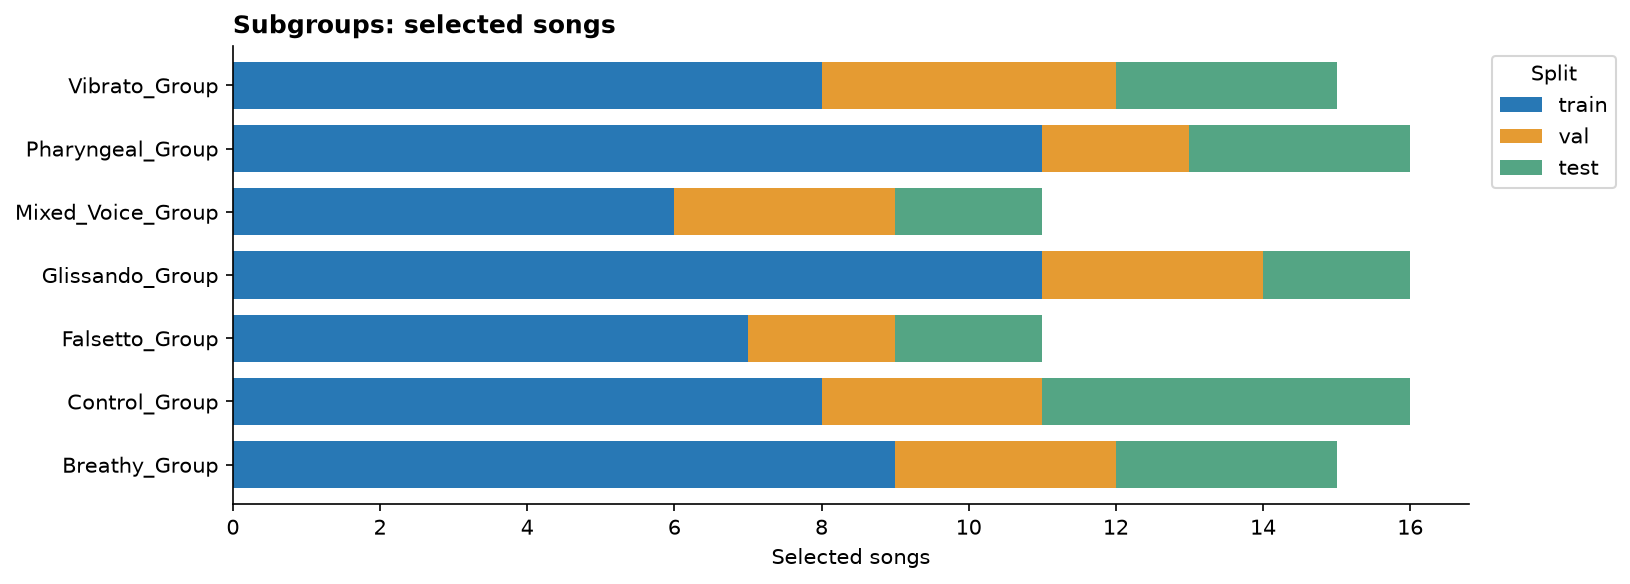

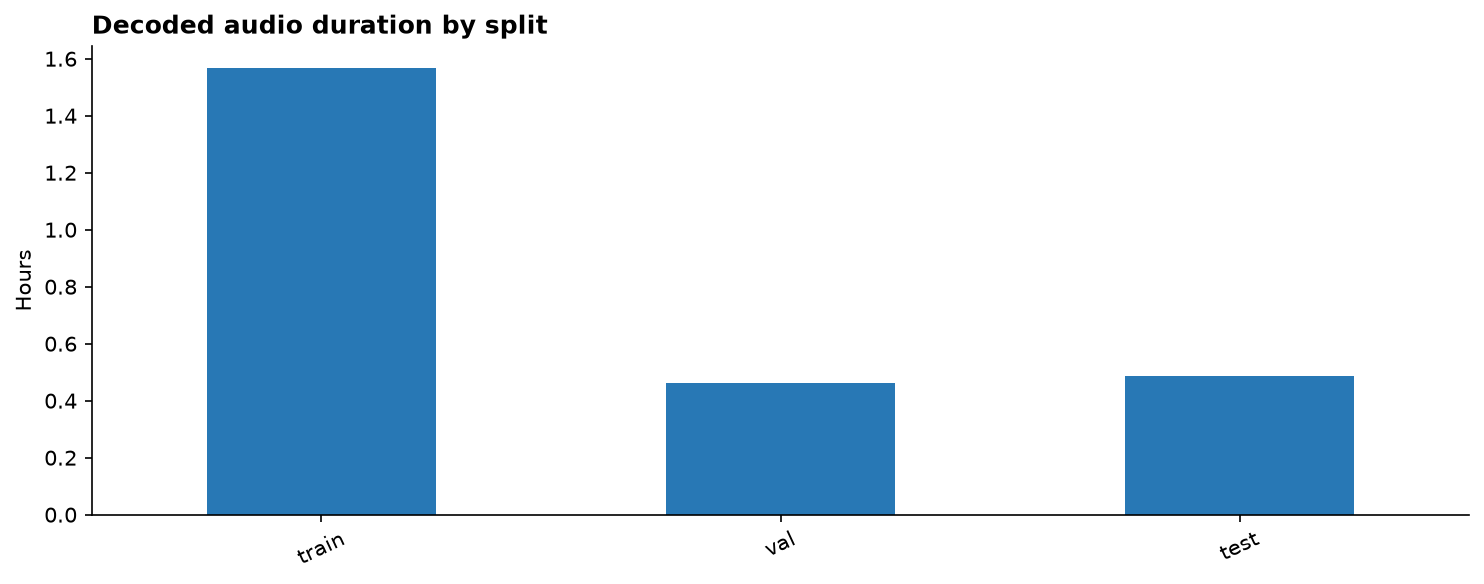

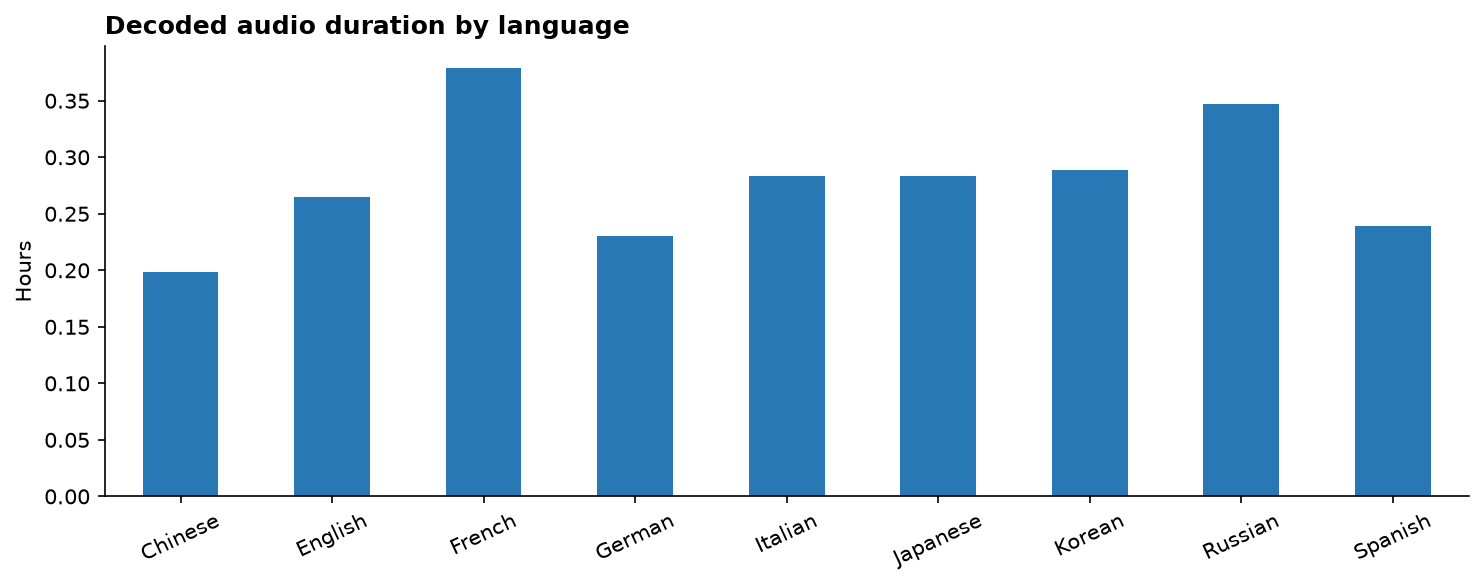

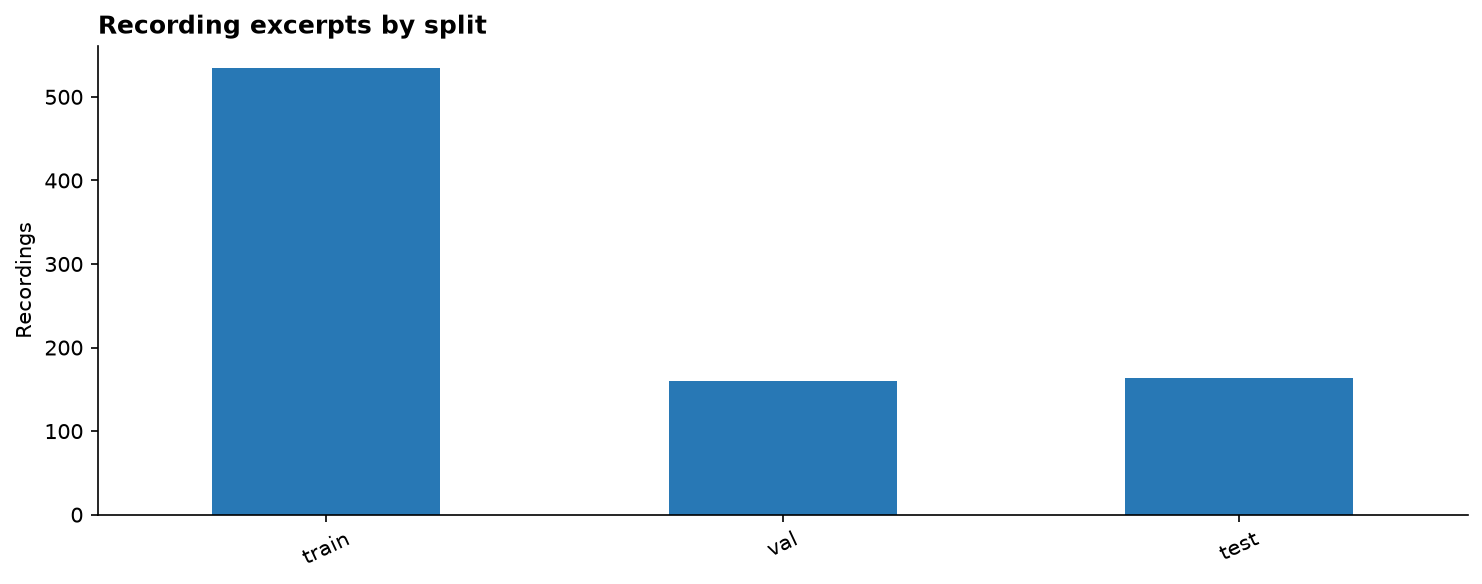

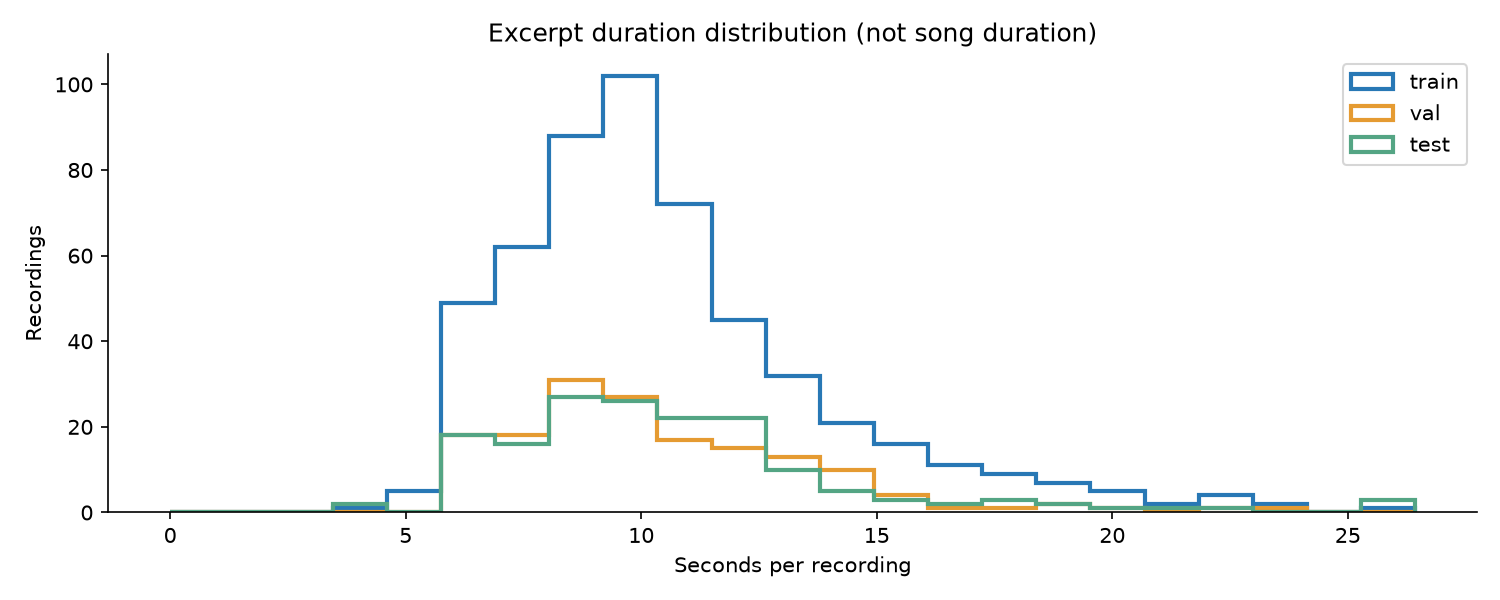

Saved PNG charts: 9


In [9]:
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':150,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
colors=['#2878B5','#E59B32','#54A584']
chart_paths=[]
for name,title in [('language_by_split','Languages: selected songs by split'),('singer_by_split','Singers: selected songs by split'),('vocal_range_by_split','Folder-derived vocal ranges: selected songs'),('technique_context_by_split','Folder technique contexts: selected songs'),('subgroup_by_split','Subgroups: selected songs')]:
    df=tables[name]
    ax=df.plot.barh(stacked=True,figsize=(11,max(4,len(df)*0.32)),color=colors,width=0.75)
    ax.set_title(title,loc='left',fontweight='bold'); ax.set_xlabel('Selected songs'); ax.set_ylabel(''); ax.legend(title='Split',bbox_to_anchor=(1.01,1),loc='upper left')
    ax.figure.tight_layout()
    path=CHARTS_OUT/(name+'.png'); ax.figure.savefig(path,bbox_inches='tight'); ax.figure.savefig(path.with_suffix('.svg'),bbox_inches='tight'); plt.close(ax.figure)
    chart_paths.append(path); display(Image(filename=str(path)))
for name,column,title,ylabel in [('duration_by_split','total_hours','Decoded audio duration by split','Hours'),('duration_by_language','total_hours','Decoded audio duration by language','Hours'),('recordings_by_split','recordings','Recording excerpts by split','Recordings')]:
    ax=tables[name][column].plot.bar(figsize=(10,4),color='#2878B5',rot=25)
    ax.set_title(title,loc='left',fontweight='bold'); ax.set_ylabel(ylabel); ax.set_xlabel(''); ax.figure.tight_layout()
    path=CHARTS_OUT/(name+'.png'); ax.figure.savefig(path,bbox_inches='tight'); ax.figure.savefig(path.with_suffix('.svg'),bbox_inches='tight'); plt.close(ax.figure)
    chart_paths.append(path); display(Image(filename=str(path)))
fig,ax=plt.subplots(figsize=(10,4))
for split,color in zip(SPLITS,colors):
    ax.hist(durations.loc[durations.split==split,'duration_seconds'],bins=np.linspace(0,durations.duration_seconds.max(),24),histtype='step',linewidth=2,label=split,color=color)
ax.set(title='Excerpt duration distribution (not song duration)',xlabel='Seconds per recording',ylabel='Recordings'); ax.legend(); fig.tight_layout()
path=CHARTS_OUT/'excerpt_duration_histogram.png'; fig.savefig(path); fig.savefig(path.with_suffix('.svg')); plt.close(fig)
chart_paths.append(path); display(Image(filename=str(path)))
print('Saved PNG charts:',len(chart_paths))

## 9. EDA summary report

In [10]:
def markdown_table(df):
    view=df.reset_index()
    def fmt(v): return f'{v:.4f}' if isinstance(v,(float,np.floating)) else str(v).replace('|','\|')
    lines=['| '+' | '.join(map(str,view.columns))+' |','| '+' | '.join(['---']*len(view.columns))+' |']
    lines += ['| '+' | '.join(fmt(v) for v in row)+' |' for row in view.itertuples(index=False,name=None)]
    return '\n'.join(lines)
caveats=[
'This is a balanced benchmark sample, not a natural-distribution sample.',
'Vocal range is folder/singer-derived, not measured pitch.',
'Technique context/subgroup is folder-derived and may not equal actual phoneme-level flags.',
'Title identity was canonicalized conservatively; title review is not exhaustive musicological composition verification.',
'Test summaries are descriptive metadata/integrity checks only; no test inference, reference-metric evaluation or config selection was performed.',
'No Basic Pitch installation or inference was performed. No transcription accuracy is claimed.',
'Audio durations here are read from headers and agree with the original full-decode validation. Excerpts, not full-song duration, are summarized.'
]
lines=['# Frozen GTSinger sample: EDA summary','',f'Sample root: `{SAMPLE_ROOT}`',f'Hugging Face revision: `{source["revision"]}`','',f'Frozen verification: PASSED. {len(songs)} unique canonical song IDs; 60 train / 20 val / 20 test.',f'Coverage: {songs.language.nunique()} languages, {songs.singer.nunique()} singers, {songs.vocal_range.nunique()} ranges.',f'Recordings: {len(recordings)}; selected files: {len(files)}; audio hours: {durations.duration_seconds.sum()/3600:.4f}.','', 'No sample regeneration, replacements, reshuffling or source rewrites.']
for name,table in tables.items():
    if name=='excerpts_per_song': continue
    lines += ['', '## '+name.replace('_',' ').title(),'',markdown_table(table)]
lines += ['','## Charts','']+[f'![{p.stem}](../eda_outputs/charts/{p.name})' for p in chart_paths]
lines += ['','## Missing / invalid files','',f'{len(issues)} issues. Full checks: eda_outputs/file_integrity_checks.csv; missing_invalid_files.csv.','', '## Caveats','']+['- '+s for s in caveats]
(REPORTS_OUT/'eda_summary.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('Written:',REPORTS_OUT/'eda_summary.md')

Written: C:\Users\dtpz2\Documents\Daphne documents\projects\datamining\GTSinger_100_unique_sample\reports\eda_summary.md


<>:3: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
<>:3: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
C:\Users\dtpz2\AppData\Local\Temp\ipykernel_21172\884279639.py:3: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
  def fmt(v): return f'{v:.4f}' if isinstance(v,(float,np.floating)) else str(v).replace('|','\|')


## 10. Basic Pitch availability — inspection only
No Basic Pitch import, installation, model loading or inference. Official upstream documentation was consulted for preparation; its documented Python compatibility range does not include this project’s Python 3.14.

In [11]:
bp_spec=importlib.util.find_spec('basic_pitch')
try: bp_version=importlib.metadata.version('basic-pitch')
except importlib.metadata.PackageNotFoundError: bp_version=None
bp_cli=shutil.which('basic-pitch')
bp_environment=dict(python=sys.version,executable=sys.executable,platform=platform.platform(),module_discoverable=bp_spec is not None,distribution_version=bp_version,cli_path=bp_cli,import_attempted=False,installation_attempted=False,inference_attempted=False,upstream_documented_python_versions=['3.7','3.8','3.9','3.10','3.11'],documentation_url='https://github.com/spotify/basic-pitch#installation',api_reference='https://github.com/spotify/basic-pitch/blob/main/basic_pitch/inference.py',status='not_installed' if bp_spec is None and bp_version is None else 'discovered_not_runtime_tested')
save_json(REPORTS_OUT/'basic_pitch_environment.json',bp_environment)
text='# Basic Pitch environment — Option A\n\n```json\n'+json.dumps(bp_environment,indent=2)+'\n```\n\n'
text+='No installation was attempted. The active project uses Python '+platform.python_version()+'. Upstream documents Python 3.7–3.11, so this environment is outside its documented range; that is a compatibility risk, not a measured install failure.\n\n'
text+='For a future approved installation, prefer a separate Python 3.10 environment rather than changing the frozen dataset environment. Confirm that interpreter is available first. Proposed commands (NOT executed):\n\n```powershell\npy -3.10 -m venv .venv-basicpitch\n.\\.venv-basicpitch\\Scripts\\python.exe -m pip install basic-pitch\n```\n\nThen verify import/runtime and package versions before any approved train/validation run. No test evaluation is authorized.\n'
(REPORTS_OUT/'basic_pitch_environment.md').write_text(text,encoding='utf-8')
display(pd.DataFrame([bp_environment]).T.rename(columns={0:'value'}))

,value
python,"3.14.6 | packaged by Anaconda, Inc. | (main, J..."
executable,C:\Users\dtpz2\Documents\Daphne documents\proj...
platform,Windows-10-10.0.19045-SP0
module_discoverable,False
distribution_version,None
cli_path,None
import_attempted,False
installation_attempted,False
inference_attempted,False
upstream_documented_python_versions,"[3.7, 3.8, 3.9, 3.10, 3.11]"


## 11. Prepare input manifests and candidate configurations
The test manifest is only a locked index. Preparing it does not run evaluation. Candidate settings are predeclared examples, not validated winners.

In [12]:
audio_hashes=files.loc[files.role=='audio',['recording_id','local_sha256']]
prepared=recordings[['sample_id','recording_id','canonical_song_id','split','language','singer','audio_path','json_path','musicxml_path','textgrid_path']].merge(audio_hashes,on='recording_id',validate='one_to_one')
for split in SPLITS:
    subset=prepared.loc[prepared.split==split].copy()
    filename='input_test_locked.csv' if split=='test' else f'input_{split}.csv'
    subset.to_csv(BP_OUT/filename,index=False)
    print(filename,len(subset),'recordings')
params=dict(onset_threshold=0.5,frame_threshold=0.3,minimum_note_length=127.7,minimum_frequency=None,maximum_frequency=None,multiple_pitch_bends=False,melodia_trick=True,midi_tempo=120)
run_specs=[('run_001_default',params),('run_002_higher_thresholds',dict(params,onset_threshold=0.6,frame_threshold=0.4)),('run_003_lower_thresholds',dict(params,onset_threshold=0.4,frame_threshold=0.2))]
config_rows=[]
for name,parameters in run_specs:
    directory=BP_OUT/name; directory.mkdir(exist_ok=True)
    if (directory/'execution.json').exists(): raise RuntimeError('Existing executed run must not be overwritten: '+name)
    for subdir in ['predictions','metrics']: (directory/subdir).mkdir(exist_ok=True)
    config=dict(name=name,status='prepared_not_run',splits=['train','val'],parameters=parameters,source_revision=source['revision'],reference_accuracy_metrics_implemented=False,final_test_enabled=False,source_manifest_sha256={p.name:sha(p) for p in [SELECTED_100_CSV,SELECTED_RECORDINGS_CSV,SELECTED_FILES_CSV,SPLIT_MANIFEST_CSV]},parameter_source='https://github.com/spotify/basic-pitch/blob/main/basic_pitch/inference.py')
    save_json(directory/'config.json',config)
    prepared.loc[prepared.split.isin(['train','val'])].to_csv(directory/'input_manifest.csv',index=False)
    save_json(directory/'metrics/status.json',dict(status='not_run',attempted=0,successful=0,failed=0,transcription_accuracy=None))
    (directory/'runtime.log').write_text('NOT RUN. Option A: preparation only. No model loaded; no inference attempted.\n',encoding='utf-8')
    (directory/'report.md').write_text('# '+name+'\n\nPrepared only; no inference performed. Predictions are intentionally empty.\n\nTrain/validation input only. No measured accuracy, no runtime benchmark, no chosen config.\n',encoding='utf-8')
    config_rows.append(dict(config=name,status='prepared_not_run',attempted=0,successful=0,failed=0,onset_threshold=parameters['onset_threshold'],frame_threshold=parameters['frame_threshold'],chosen=False))
comparison=pd.DataFrame(config_rows)
comparison.to_csv(BP_OUT/'validation_config_comparison.csv',index=False)
save_json(BP_OUT/'test_lock.json',dict(locked=True,chosen_config=None,validation_selection_complete=False,final_test_authorized=False,final_test_run=False,allowed_actions=['read-only integrity checks','descriptive EDA','prepare locked manifest']))
display(comparison)

input_train.csv 534 recordings
input_val.csv 160 recordings
input_test_locked.csv 164 recordings


,config,status,attempted,successful,failed,onset_threshold,frame_threshold,chosen
0,run_001_default,prepared_not_run,0,0,0,0.5,0.3,False
1,run_002_higher_thresholds,prepared_not_run,0,0,0,0.6,0.4,False
2,run_003_lower_thresholds,prepared_not_run,0,0,0,0.4,0.2,False


## 12. Prepared train/validation runner and validation comparison
This writes an executable runner but does not invoke it. The runner requires an explicit approval flag, rejects test inputs, keeps recording IDs in output paths to avoid repeated clip-name collisions, and logs real output statistics. Its model execution path remains untested because inference and installation are not authorized.

In [13]:
RUNNER_SOURCE = '"""Prepared runner: never invoked for inference by Option A; test split is always rejected.\nAPI reference: https://github.com/spotify/basic-pitch/blob/main/basic_pitch/inference.py\n"""\nimport argparse,csv,hashlib,json,sys,time,traceback,contextlib,importlib.metadata\nfrom pathlib import Path\n\ndef digest(path):\n    h=hashlib.sha256()\n    with path.open(\'rb\') as f:\n        for b in iter(lambda:f.read(1048576),b\'\'): h.update(b)\n    return h.hexdigest()\n\ndef main():\n    ap=argparse.ArgumentParser(description=__doc__)\n    ap.add_argument(\'--sample-root\',type=Path,default=Path(__file__).resolve().parents[1])\n    ap.add_argument(\'--config\',type=Path,required=True)\n    ap.add_argument(\'--execute-approved-train-val\',action=\'store_true\')\n    args=ap.parse_args()\n    if not args.execute_approved_train_val: ap.error(\'Inference disabled. Obtain user approval before supplying --execute-approved-train-val.\')\n    root=args.sample_root.resolve(); config_path=args.config.resolve(); out=config_path.parent\n    if not out.is_relative_to(root/\'basic_pitch_runs\'): ap.error(\'Config/output must be inside basic_pitch_runs.\')\n    config=json.loads(config_path.read_text(encoding=\'utf-8\'))\n    splits=config.get(\'splits\',[])\n    if not splits or not set(splits)<= {\'train\',\'val\'}: ap.error(\'TEST LOCKED: train/val only.\')\n    if (out/\'execution.json\').exists(): ap.error(\'Run already attempted. Use a new numbered run folder; do not overwrite.\')\n    def load(name):\n        with (root/name).open(encoding=\'utf-8\',newline=\'\') as f: return list(csv.DictReader(f))\n    manifests=[\'selected_100.csv\',\'selected_recordings.csv\',\'selected_files.csv\',\'split_manifest.csv\']\n    before={n:digest(root/n) for n in manifests}\n    records=[r for r in load(\'selected_recordings.csv\') if r[\'split\'] in splits]\n    if not records: ap.error(\'Empty train/val input selection.\')\n    audio_files={r[\'recording_id\']:r for r in load(\'selected_files.csv\') if r[\'role\']==\'audio\'}\n    for r in records:\n        path=(root/r[\'audio_path\']).resolve()\n        if not path.is_relative_to(root) or digest(path)!=audio_files[r[\'recording_id\']][\'local_sha256\']: ap.error(\'Input integrity failure: \'+r[\'recording_id\'])\n    with (out/\'input_manifest.csv\').open(\'w\',encoding=\'utf-8\',newline=\'\') as f:\n        writer=csv.DictWriter(f,fieldnames=list(records[0])); writer.writeheader(); writer.writerows(records)\n    (out/\'predictions\').mkdir(exist_ok=True); (out/\'metrics\').mkdir(exist_ok=True)\n    stamp=dict(status=\'started\',splits=splits,config_sha256=digest(config_path),python=sys.version,accuracy_metrics_implemented=False,source_manifest_sha256=before)\n    (out/\'execution.json\').write_text(json.dumps(stamp,indent=2),encoding=\'utf-8\')\n    stats=[]; start=time.perf_counter()\n    try:\n        with (out/\'runtime.log\').open(\'w\',encoding=\'utf-8\') as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):\n            import numpy as np\n            from basic_pitch.inference import Model,predict\n            from basic_pitch import ICASSP_2022_MODEL_PATH\n            stamp[\'basic_pitch_version\']=importlib.metadata.version(\'basic-pitch\')\n            model=Model(ICASSP_2022_MODEL_PATH)\n            for r in records:\n                t=time.perf_counter(); row=dict(recording_id=r[\'recording_id\'],sample_id=r[\'sample_id\'],split=r[\'split\'],status=\'failed\',note_count=0,output_file_count=0,runtime_seconds=0,error=\'\')\n                try:\n                    model_output,midi,notes=predict(root/r[\'audio_path\'],model,**config[\'parameters\'])\n                    dest=out/\'predictions\'/r[\'split\']/r[\'recording_id\']; dest.mkdir(parents=True,exist_ok=False)\n                    midi.write(str(dest/\'prediction.mid\')); np.savez_compressed(dest/\'model_output.npz\',**model_output)\n                    with (dest/\'note_events.csv\').open(\'w\',encoding=\'utf-8\',newline=\'\') as f:\n                        w=csv.writer(f); w.writerow([\'start_seconds\',\'end_seconds\',\'midi_pitch\',\'amplitude\',\'pitch_bends_json\'])\n                        for onset,offset,pitch,amplitude,bends in notes: w.writerow([float(onset),float(offset),int(pitch),float(amplitude),json.dumps(None if bends is None else [int(b) for b in bends])])\n                    row.update(status=\'passed\',note_count=len(notes),output_file_count=3)\n                except Exception as exc: row[\'error\']=str(exc); traceback.print_exc()\n                row[\'runtime_seconds\']=time.perf_counter()-t; stats.append(row)\n                with (out/\'runtime_events.jsonl\').open(\'a\',encoding=\'utf-8\') as f: f.write(json.dumps(row)+\'\\n\')\n    except Exception as exc:\n        stamp.update(status=\'blocked\',error=str(exc))\n        raise\n    finally:\n        after={n:digest(root/n) for n in manifests}\n        unchanged=before==after and all(digest(root/r[\'audio_path\'])==audio_files[r[\'recording_id\']][\'local_sha256\'] for r in records)\n        stamp.update(runtime_seconds=time.perf_counter()-start,inputs_unchanged=unchanged,attempted=len(stats),successful=sum(r[\'status\']==\'passed\' for r in stats),failed=sum(r[\'status\']==\'failed\' for r in stats))\n        if stamp[\'status\']==\'started\': stamp[\'status\']=\'completed\' if not stamp[\'failed\'] else \'completed_with_failures\'\n        (out/\'execution.json\').write_text(json.dumps(stamp,indent=2),encoding=\'utf-8\')\n        if stats:\n            with (out/\'metrics/output_stats.csv\').open(\'w\',encoding=\'utf-8\',newline=\'\') as f:\n                w=csv.DictWriter(f,fieldnames=list(stats[0])); w.writeheader(); w.writerows(stats)\n        (out/\'report.md\').write_text(\'# Basic Pitch train/validation run\\n\\n```json\\n\'+json.dumps(stamp,indent=2)+\'\\n```\\n\\nOutput statistics only. No reference-based accuracy metrics or test inference.\\n\',encoding=\'utf-8\')\n        if not unchanged: raise RuntimeError(\'Input preservation failed\')\nif __name__==\'__main__\': main()\n'
runner_path=SAMPLE_ROOT/'notebooks/basic_pitch_train_val.py'
runner_path.write_text(RUNNER_SOURCE,encoding='utf-8')
# Syntax check only: compile does not import Basic Pitch or execute the runner.
compile(RUNNER_SOURCE,str(runner_path),'exec')
print('Prepared (not executed):',runner_path)
print('Future approved command: <basic-pitch-env-python> notebooks/basic_pitch_train_val.py --config basic_pitch_runs/run_001_default/config.json --execute-approved-train-val')
summary='# Basic Pitch tuning summary — NOT RUN\n\nOption A authorizes preparation only. No Basic Pitch installation or inference occurred.\n\n'+markdown_table(comparison)+'\n\nNo validation scores exist; no configuration has been selected or locked. Output success statistics, when available, must not be described as transcription accuracy. Reference onset/pitch/offset metrics are not implemented in this phase.\n\nThe runner has been syntax/safety checked only; the inference path requires a compatible approved Basic Pitch installation and a future real smoke test.\n'
(REPORTS_OUT/'basic_pitch_tuning_summary.md').write_text(summary,encoding='utf-8')

Prepared (not executed): C:\Users\dtpz2\Documents\Daphne documents\projects\datamining\GTSinger_100_unique_sample\notebooks\basic_pitch_train_val.py
Future approved command: <basic-pitch-env-python> notebooks/basic_pitch_train_val.py --config basic_pitch_runs/run_001_default/config.json --execute-approved-train-val


948

## 13. Final test stays locked
No final-test run folder or predictions are created. A later, separately approved phase must select a configuration using validation, freeze that configuration, and enforce a once-only test run.

In [14]:
assert RUN_BASIC_PITCH is False and RUN_FINAL_TEST is False
if (BP_OUT/'final_test_locked').exists():
    raise RuntimeError('Unexpected final-test run folder: inspect manually; do not overwrite or rerun.')
(REPORTS_OUT/'final_test_summary.md').write_text('# Final test — NOT RUN\n\nRUN_FINAL_TEST=False. No config has been chosen using validation. No inference or test metrics were generated. Only read-only integrity checks, descriptive summaries and a locked input manifest include test data.\n\nSeparate explicit approval is required after validation config selection; the prepared train/validation runner rejects test.\n',encoding='utf-8')
print('Final test run: no. Config chosen: none. Test lock remains active.')

Final test run: no. Config chosen: none. Test lock remains active.


## 14. Final preservation audit and status
Rehash all protected files, compare to the initial baseline and save the result. This does not rerun the old dataset-generation/reproduction scripts.

In [15]:
after=snapshot(SAMPLE_ROOT)
changed=sorted(k for k in set(baseline)&set(after) if baseline[k]!=after[k])
removed=sorted(set(baseline)-set(after)); added=sorted(set(after)-set(baseline))
unchanged=not changed and not removed and not added
preservation=dict(passed=unchanged,protected_files=len(baseline),changed=changed,removed=removed,added=added,method='SHA256 of all files outside approved output directories; baseline captured after authorized frozen-marker creation')
save_json(REPORTS_OUT/'frozen_preservation_report.json',preservation)
if not unchanged: raise RuntimeError('Frozen inputs changed: '+str(preservation))
status=dict(scope='A: verification, EDA, Basic Pitch preparation only',sample_root=str(SAMPLE_ROOT),source_revision=source['revision'],frozen_verification_passed=all(checks.values()),raw_files_unchanged=unchanged,protected_files=len(baseline),selected_songs=len(songs),selected_recordings=len(recordings),selected_files=len(files),split_song_counts=songs.split.value_counts().to_dict(),language_count=songs.language.nunique(),singer_count=songs.singer.nunique(),range_count=songs.vocal_range.nunique(),audio_hours=float(durations.duration_seconds.sum()/3600),eda_report='reports/eda_summary.md',chart_count=len(chart_paths),basic_pitch_status=bp_environment['status'],basic_pitch_installation_attempted=False,basic_pitch_inference_run=False,chosen_config=None,final_test_run=False,run_folders=[name for name,_ in run_specs])
save_json(REPORTS_OUT/'phase_a_status.json',status)
lock=subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True,check=True)
(REPORTS_OUT/'phase_a_requirements_lock.txt').write_text(lock.stdout,encoding='utf-8')
print(json.dumps(status,indent=2))
print('Frozen sample verified: yes')
print('EDA report:',REPORTS_OUT/'eda_summary.md')
print('Basic Pitch status:',bp_environment['status'],'— preparation only')
print('Final test run: no')
print('Raw files modified: no')

{
  "scope": "A: verification, EDA, Basic Pitch preparation only",
  "sample_root": "C:\\Users\\dtpz2\\Documents\\Daphne documents\\projects\\datamining\\GTSinger_100_unique_sample",
  "source_revision": "4426c862beed558b7e1cb8a4dce7e8c0c83bb208",
  "frozen_verification_passed": true,
  "raw_files_unchanged": true,
  "protected_files": 12230,
  "selected_songs": 100,
  "selected_recordings": 858,
  "selected_files": 3432,
  "split_song_counts": {
    "train": 60,
    "test": 20,
    "val": 20
  },
  "language_count": 9,
  "singer_count": 20,
  "range_count": 4,
  "audio_hours": 2.5149001273148146,
  "eda_report": "reports/eda_summary.md",
  "chart_count": 9,
  "basic_pitch_status": "not_installed",
  "basic_pitch_installation_attempted": false,
  "basic_pitch_inference_run": false,
  "chosen_config": null,
  "final_test_run": false,
  "run_folders": [
    "run_001_default",
    "run_002_higher_thresholds",
    "run_003_lower_thresholds"
  ]
}
Frozen sample verified: yes
EDA report: C:\